In [1]:
#| include: false
import matplotlib.pyplot as plt
import numpy as np
from scipy.constants import Boltzmann as k_B
from scipy.constants import elementary_charge as e
from scipy.constants import epsilon_0

plt.rcParams.update(
    {
        "font.size": 14,
        "axes.labelsize": 15,
        "axes.titlesize": 17,
        "legend.fontsize": 11,
        "lines.linewidth": 2.5,
    }
)


def bjerrum_length(T, eps_r):
    """Bjerrum length in Å."""
    return e**2 / (4 * np.pi * epsilon_0 * eps_r * k_B * T) * 1e10

## 1. Question: why do salt ions separate in water?

Day 1: ion–ion interactions are among the strongest non-covalent interactions, roughly **50–500 kJ/mol**.

Yet NaCl dissolves readily in water, and the ions move about independently.

**Question:** What must water do to the interaction between Na$^+$ and Cl$^-$? Keep your answer; we return to it in section 4. (Why salt dissolves at all is day 4.)

## 2. Coulomb's law

Two point charges $q_1 = z_1e$ and $q_2 = z_2e$ at distance $r$ in vacuum:

$$u(r) = \frac{q_1 q_2}{4\pi\epsilon_0 r}$$

- like charges repel ($u>0$), unlike charges attract ($u<0$)
- **pairwise additive**: the energy of many charges is a sum over all pairs
- **long-ranged**: $1/r$ decays far more slowly than dispersion, $1/r^6$ (day 1)

Per mole, with $r$ in Å:

$$u = 1389\,\frac{z_1 z_2}{r/\text{Å}}\ \mathrm{kJ/mol}$$

Dill & Bromberg write $\mathcal{C} = 1/4\pi\epsilon_0$, and $D$ for the dielectric constant $\epsilon_r$.

## Example: Na$^+$ and Cl$^-$ in vacuum

Dill Example 20.1: the ions in contact, $r = 2.8$ Å:

$$u = 1389 \times \frac{(+1)(-1)}{2.8}\ \mathrm{kJ/mol} \approx -496\ \mathrm{kJ/mol}$$

That is about $200\,RT$ at room temperature, comparable to a covalent bond.

**Question:** Will an isolated Na$^+$Cl$^-$ pair in the gas phase ever fall apart thermally?

## 3. Why do ionic crystals hold together?

:::: {.columns}
::: {.column width="45%"}
Dill Example 20.2: three charges in a line, $+e$, $-qe$, $+e$, with spacing $r$:

$$u = \frac{e^2}{4\pi\epsilon_0 r}\left(-q - q + \frac{1}{2}\right)$$

Two attractive neighbour pairs; one repulsive pair at distance $2r$.

$q$ is a free parameter: the cluster is electroneutral only at $q = 2$. How large must $q$ be to hold it together?
:::

::: {.column width="55%"}

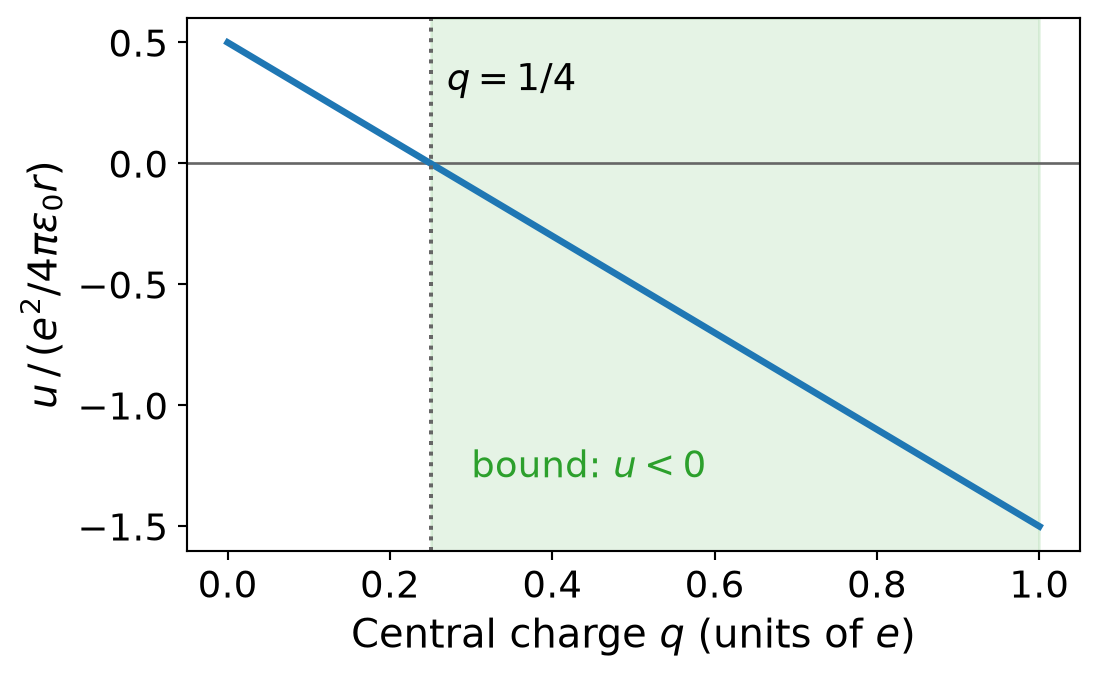

In [2]:
q = np.linspace(0, 1, 200)
u = -2 * q + 0.5

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.axhline(0, color="0.4", lw=1)
ax.plot(q, u)
ax.axvspan(0.25, 1, color="tab:green", alpha=0.12)
ax.axvline(0.25, color="0.4", ls=":", lw=1.5)
ax.text(0.27, 0.3, r"$q = 1/4$")
ax.text(0.3, -1.3, "bound: $u<0$", color="tab:green")
ax.set_xlabel(r"Central charge $q$ (units of $e$)")
ax.set_ylabel(r"$u \,/\, (e^2/4\pi\epsilon_0 r)$")
plt.show()

:::
::::

::: {.fragment}
Separated charges have $u = 0$. For $q > 1/4$ the cluster lies lower: attraction to the two neighbours beats the repulsion between the outer pair.
:::

## Lattice energy and the Madelung constant

Dill Example 20.3: NaCl crystal, nearest-neighbour distance $a = 2.81$ Å. One row through an ion; it has neighbours on both sides, so each distance appears twice (the factor 2):

$$u_{\rm row} = \frac{2e^2}{4\pi\epsilon_0 a}\left(-1 + \frac{1}{2} - \frac{1}{3} + \frac{1}{4} - \cdots\right) = -\frac{2e^2}{4\pi\epsilon_0 a}\ln 2$$

Adding all rows in three dimensions:

$$U = -1.747\,\frac{e^2 N_A}{4\pi\epsilon_0\,a} \approx -860\ \mathrm{kJ/mol}$$

The number $1.747$ is the **Madelung constant** of the NaCl lattice. Experiment: $-766$ kJ/mol.

## The lattice sum converges slowly {.nostretch}

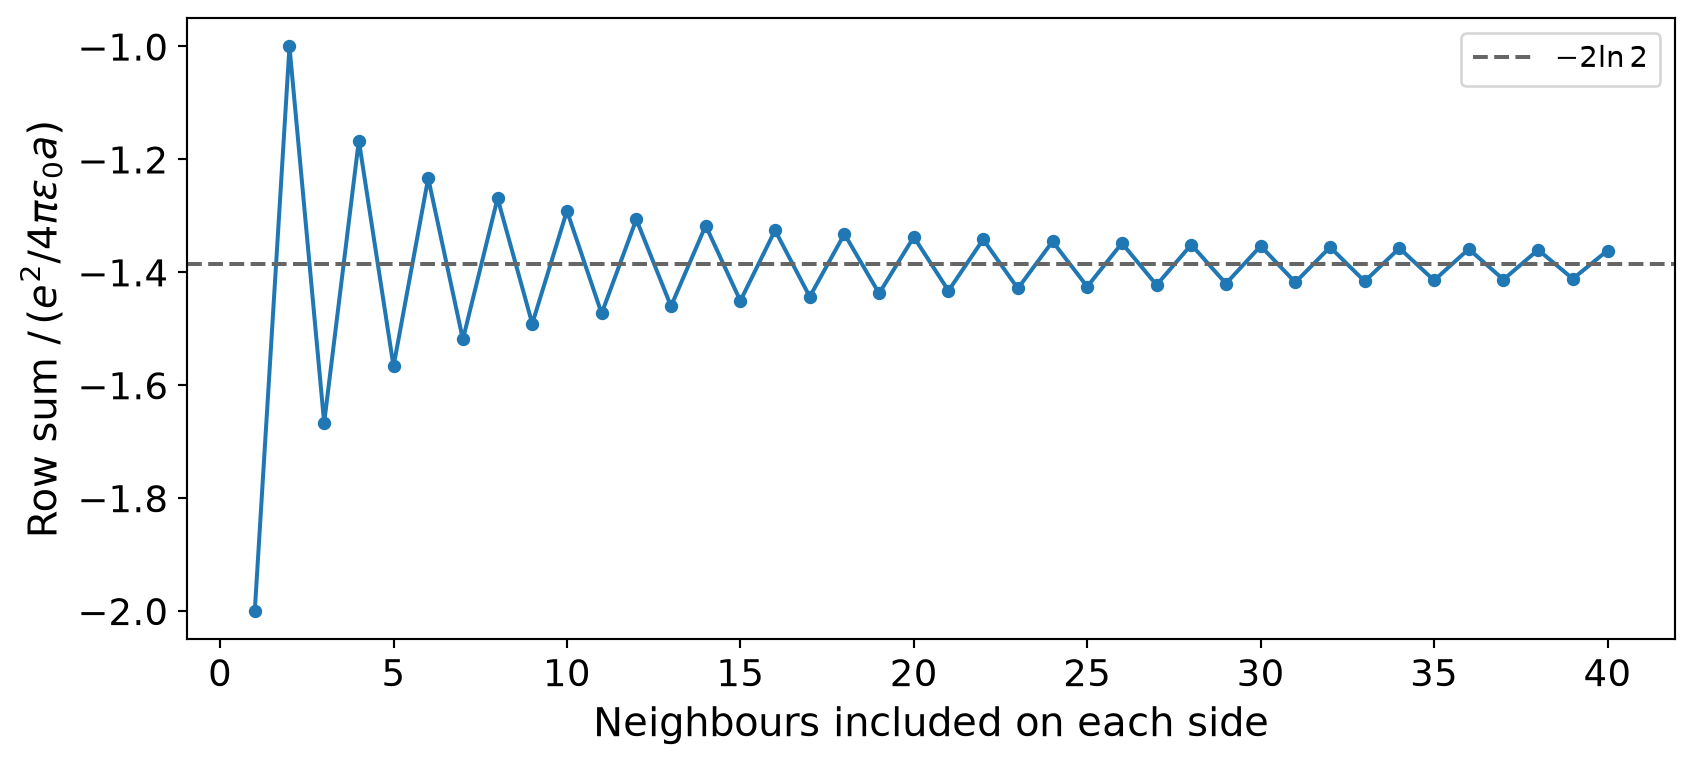

In [3]:
n = np.arange(1, 41)
partial = 2 * np.cumsum((-1.0) ** n / n)  # neighbours on both sides of the ion

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(n, partial, "o-", ms=4, lw=1.5)
ax.axhline(-2 * np.log(2), color="0.4", ls="--", lw=1.5, label=r"$-2\ln 2$")
ax.set_xlabel("Neighbours included on each side")
ax.set_ylabel(r"Row sum $/\,(e^2/4\pi\epsilon_0 a)$")
ax.legend()
plt.show()

Long range means distant ions still matter: stopping at nearest neighbours gives a badly wrong answer.

**Question:** The estimate, $-860$ kJ/mol, is more negative than experiment, $-766$ kJ/mol. What did the model leave out?

## 4. Charge interactions are weaker in media

In a medium with relative dielectric constant $\epsilon_r$:

$$u(r) = \frac{q_1 q_2}{4\pi\epsilon_0\epsilon_r r}$$

:::: {.columns}
::: {.column style="width: 45%; font-size: 85%"}
| Medium | $T$ (°C) | $\epsilon_r$ |
|---|---:|---:|
| Vacuum | | 1 |
| Air | 0 | 1.0006 |
| Heptane | 30 | 1.92 |
| Methanol | 25 | 33 |
| Water | 25 | 78.5 |
| Formamide | 20 | 109 |

Selected from Dill Table 20.1.
:::

::: {.column width="55%"}
Polar solvent molecules turn their dipoles towards each ion and partly cancel its field: the medium **screens** the charges. More on this mechanism on day 3.
:::
::::

## Back to the question: NaCl in water

Dill Example 20.4: the same contact pair, $a = 2.81$ Å, now in water with $\epsilon_r = 78.5$:

$$u = \frac{1389}{78.5}\times\frac{(+1)(-1)}{2.81}\ \mathrm{kJ/mol} \approx -6.3\ \mathrm{kJ/mol} \approx -2.5\,RT$$

- in vacuum: about $-200\,RT$; in water: about $-2.5\,RT$
- once in water, a contact ion pair is held by only about $2.5\,RT$, so the entropy of free ions wins: dissolved salts are mostly dissociated
- whether a salt dissolves at all is a different balance: lattice energy against ion solvation (the Born energy), day 4

## 5. The Bjerrum length

The distance at which two unit charges interact with exactly $k_BT$:

$$\ell_B = \frac{e^2}{4\pi\epsilon_0\epsilon_r k_BT}
\qquad\Longrightarrow\qquad
\frac{u(r)}{k_BT} = \frac{\ell_B\, z_1 z_2}{r}$$

- one length per solvent and temperature sums up how strong charge interactions are
- $r < \ell_B$: electrostatics beats thermal motion; $r > \ell_B$: thermal motion wins
- at 298 K: $\ell_B \approx 560$ Å in vacuum and $\approx 7.1$ Å in water
- working in units of $k_BT$ removes all the constants: only $\ell_B$, $z$ and $r$ remain

## Charge interactions in different media

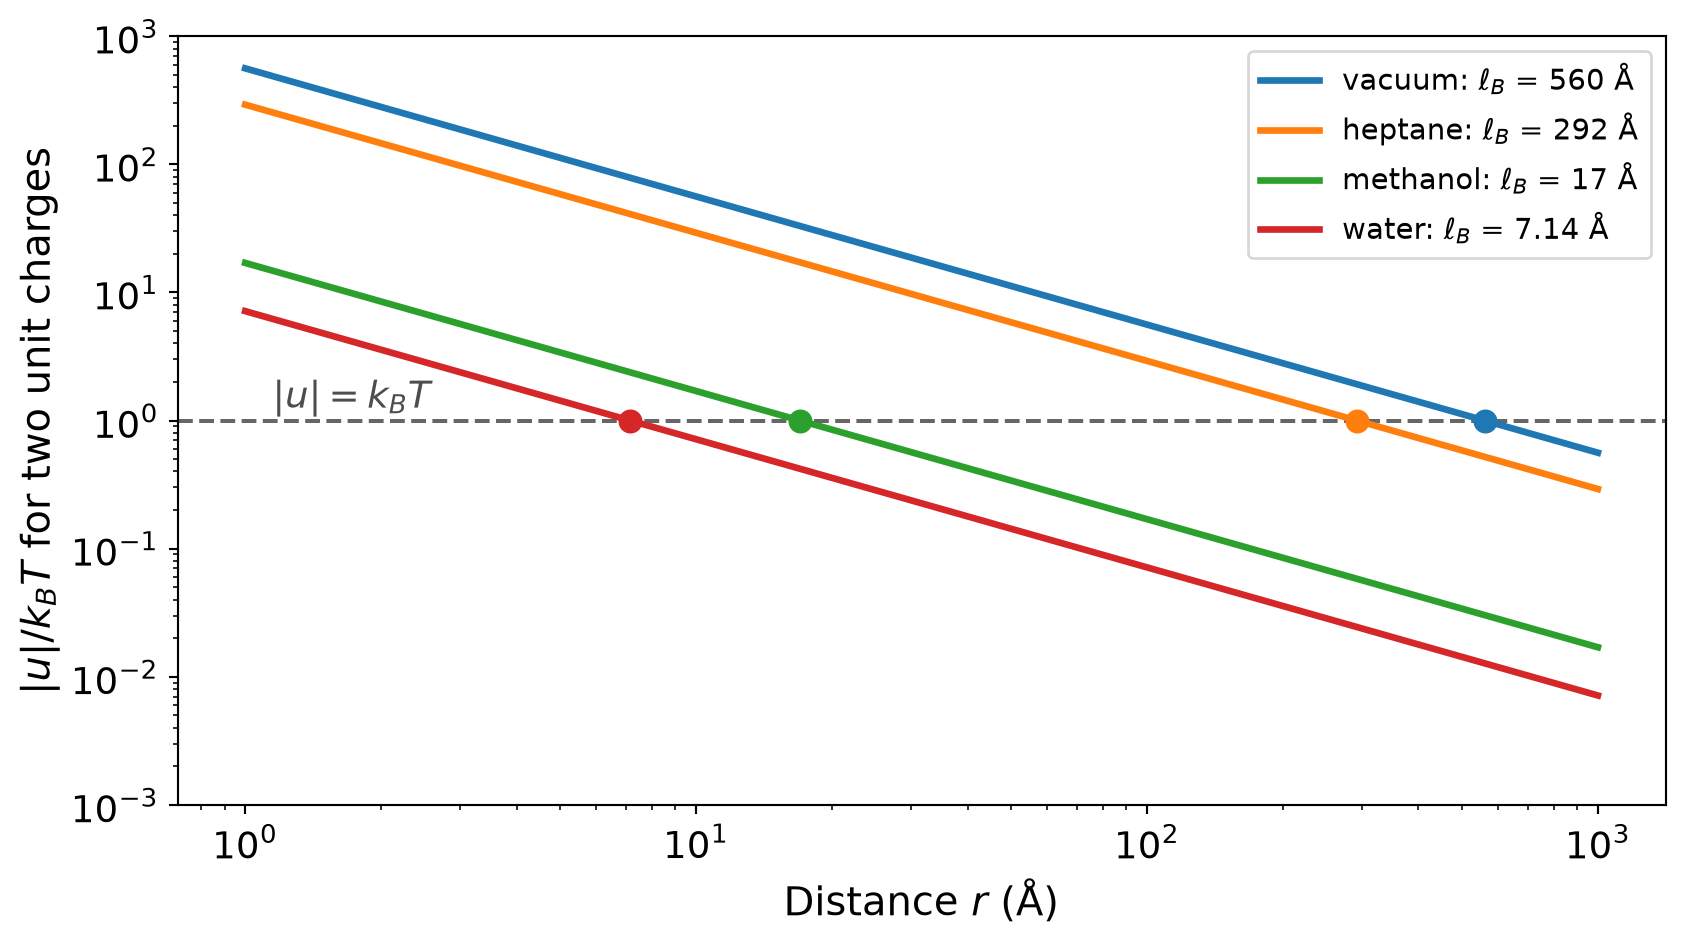

In [4]:
T = 298.15
r = np.logspace(0, 3, 300)  # Å
media = [("vacuum", 1.0), ("heptane", 1.92), ("methanol", 33), ("water", 78.5)]

fig, ax = plt.subplots(figsize=(10, 5.2))
ax.axhline(1, color="0.4", ls="--", lw=1.5)
ax.text(1.15, 1.25, r"$|u| = k_BT$", color="0.3")
for name, eps_r in media:
    lB = bjerrum_length(T, eps_r)
    (line,) = ax.plot(r, lB / r, label=rf"{name}: $\ell_B$ = {lB:.3g} Å")
    ax.plot(lB, 1, "o", color=line.get_color(), ms=8)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_ylim(1e-3, 1e3)
ax.set_xlabel(r"Distance $r$ (Å)")
ax.set_ylabel(r"$|u|/k_BT$ for two unit charges")
ax.legend(loc="upper right")
plt.show()

Each line crosses $|u| = k_BT$ at that medium's Bjerrum length (after Dill Fig. 20.4).

## Energy units

| | per molecule | per mole |
|---|---|---|
| thermal energy at 298 K | $k_BT = 4.12\times10^{-21}$ J | $RT = 2.48$ kJ/mol |
| conversion | $u/k_BT$ | $=\ u_{\rm molar}/RT$ |

- $1$ kcal $= 4.184$ kJ
- electric potential in natural units: $k_BT/e = 25.7$ mV at 298 K

## Question: K$^+$ and Cl$^-$ in vacuum

**Question** (2 min, in pairs): K$^+$ and Cl$^-$ are 20 Å apart in vacuum at 298 K. What is their interaction energy in $k_BT$ and in kJ/mol? Is that large?

::: {.fragment}
$$\frac{u}{k_BT} = -\frac{\ell_B}{r} = -\frac{560}{20} = -28 \qquad u = -28\,RT \approx -69\ \mathrm{kJ/mol}$$

Even 20 Å apart, the ions are still strongly bound in vacuum.
:::

## 6. Forces add like vectors {.nostretch}

The force follows from the energy, $f = -du/dr$. On charge $A$ from charge $B$:

$$\mathbf f_{A} = \frac{q_A q_B}{4\pi\epsilon_0\epsilon_r r_{AB}^2}\,\mathbf{\hat r}_{AB}$$

with $\mathbf{\hat r}_{AB}$ the unit vector from $B$ to $A$. Components: $f_x = f\cos\alpha$, $f_y = f\sin\alpha$.

The total force on a charge is the **vector sum** over all other charges.

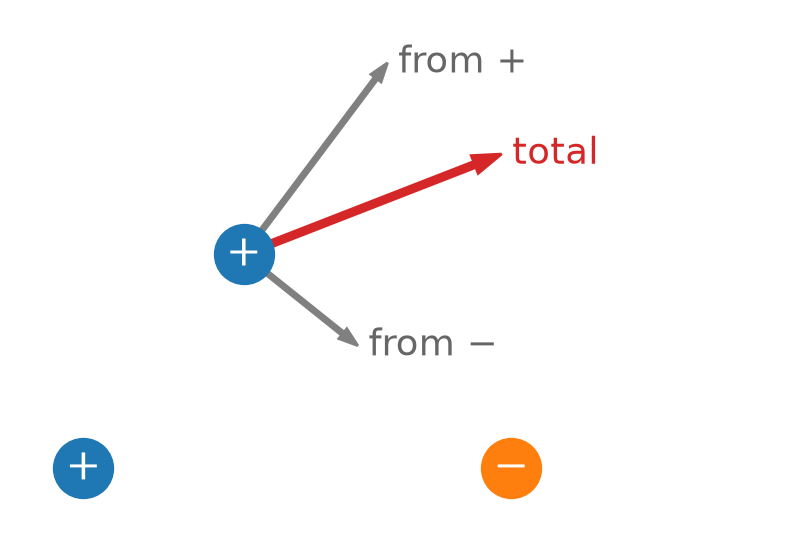

In [5]:
fixed = [(+1, np.array([0.0, 0.0])), (-1, np.array([4.0, 0.0]))]
z_test, p_test = +1, np.array([1.5, 2.0])

fig, ax = plt.subplots(figsize=(10, 3.4))
total = np.zeros(2)
for z, p in fixed:
    d = p_test - p
    f = z_test * z * d / np.linalg.norm(d) ** 3  # reduced units
    total += f
    ax.arrow(*p_test, *(14 * f), color="0.5", width=0.04, length_includes_head=True)
    sign = "+" if z > 0 else "−"
    ax.text(*(p_test + 14 * f + [0.1, 0]), f"from {sign}", color="0.4", va="center")
ax.arrow(*p_test, *(14 * total), color="tab:red", width=0.06, length_includes_head=True)
for z, p in [*fixed, (z_test, p_test)]:
    ax.plot(*p, "o", ms=22, color="tab:blue" if z > 0 else "tab:orange")
    ax.text(*p, "+" if z > 0 else "−", ha="center", va="center", color="w", fontsize=16)
ax.text(*(p_test + 14 * total + [0.1, 0]), "total", color="tab:red", va="center")
ax.set_aspect("equal")
ax.set_xlim(-0.6, 6.4)
ax.set_ylim(-0.5, 4.2)
ax.axis("off")
plt.show()

## Electric field

The field is the force per unit test charge. For a point charge $q$ (Dill Example 20.5):

$$\mathbf E(\mathbf r) = \frac{\mathbf f}{q_{\rm test}} = \frac{1}{q_{\rm test}}\,\frac{q\,q_{\rm test}}{4\pi\epsilon_0\epsilon_r r^2}\,\mathbf{\hat r} = \frac{q}{4\pi\epsilon_0\epsilon_r r^2}\,\mathbf{\hat r}$$

A **test charge** $q_{\rm test}$ is a small probe charge at $\mathbf r$ that does not disturb the other charges. The force on it is proportional to $q_{\rm test}$, so $\mathbf E$ depends only on the charges creating it. Units: V/m $=$ N/C; fields from several charges add as vectors.

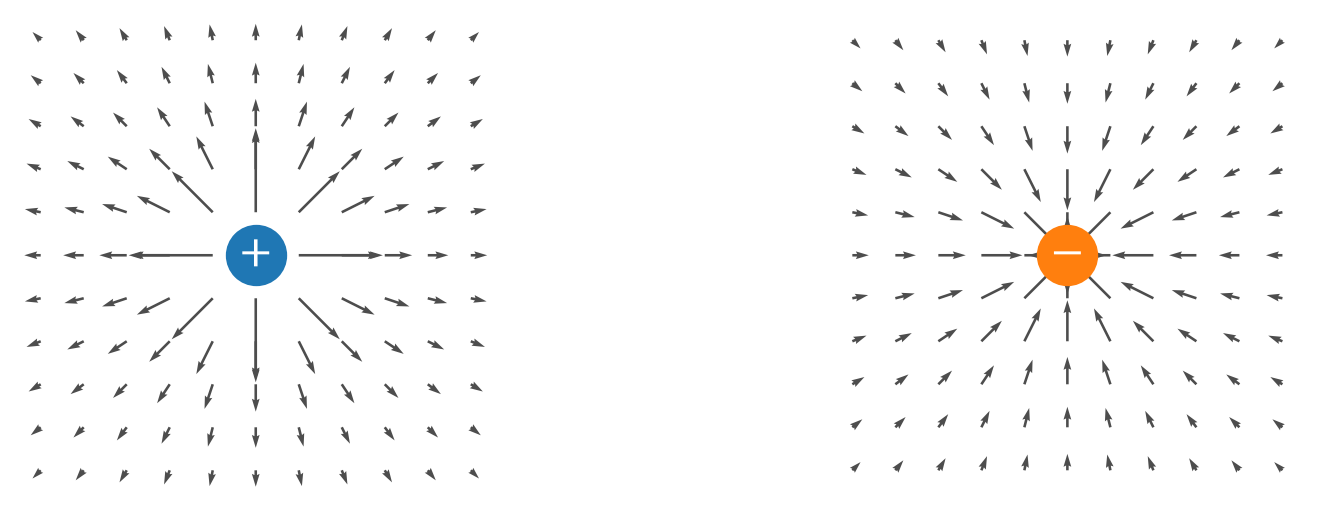

In [6]:
x, y = np.meshgrid(np.linspace(-2, 2, 11), np.linspace(-2, 2, 11))
r = np.hypot(x, y)
r[r < 0.3] = np.nan  # no arrows on top of the charge

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, z in zip(axes, (+1, -1)):
    ax.quiver(x, y, z * x / r**2, z * y / r**2, color="0.3")
    ax.plot(0, 0, "o", ms=22, color="tab:blue" if z > 0 else "tab:orange")
    ax.text(
        0, 0, "+" if z > 0 else "−", ha="center", va="center", color="w", fontsize=16
    )
    ax.set_aspect("equal")
    ax.axis("off")
plt.show()

## 7. Electric potential

The potential is the energy per unit test charge. For a point charge $q$:

$$\phi(\mathbf r) = \frac{u(\mathbf r)}{q_{\rm test}} = \frac{1}{q_{\rm test}}\,\frac{q\,q_{\rm test}}{4\pi\epsilon_0\epsilon_r r} = \frac{q}{4\pi\epsilon_0\epsilon_r r}$$

- units: V $=$ J/C; a charge $q$ placed at potential $\phi$ has energy $u = q\phi$
- in natural units, using the Bjerrum length:

$$\frac{e\,\phi(r)}{k_BT} = \frac{\ell_B\,z}{r} \qquad (k_BT/e = 25.7\ \text{mV at 298 K})$$

- potentials from several charges simply add: $\phi = \sum_i \phi_i$, numbers, not vectors

## Energy, force, potential and field

| | for a charge $q$ | per unit charge |
|---|---|---|
| **scalar** | energy $u$ | potential $\phi = u/q$ |
| **vector** | force $\mathbf f = -\nabla u$ | field $\mathbf E = \mathbf f/q = -\nabla\phi$ |

- down a column: take minus the gradient (in one dimension, $-d/dr$)
- along a row: divide by the charge
- scalars add as numbers; vectors add component by component

**Question:** Where is the force on a charge zero: where $\phi = 0$, or where $\phi$ is flat?

## Superposition: two like charges

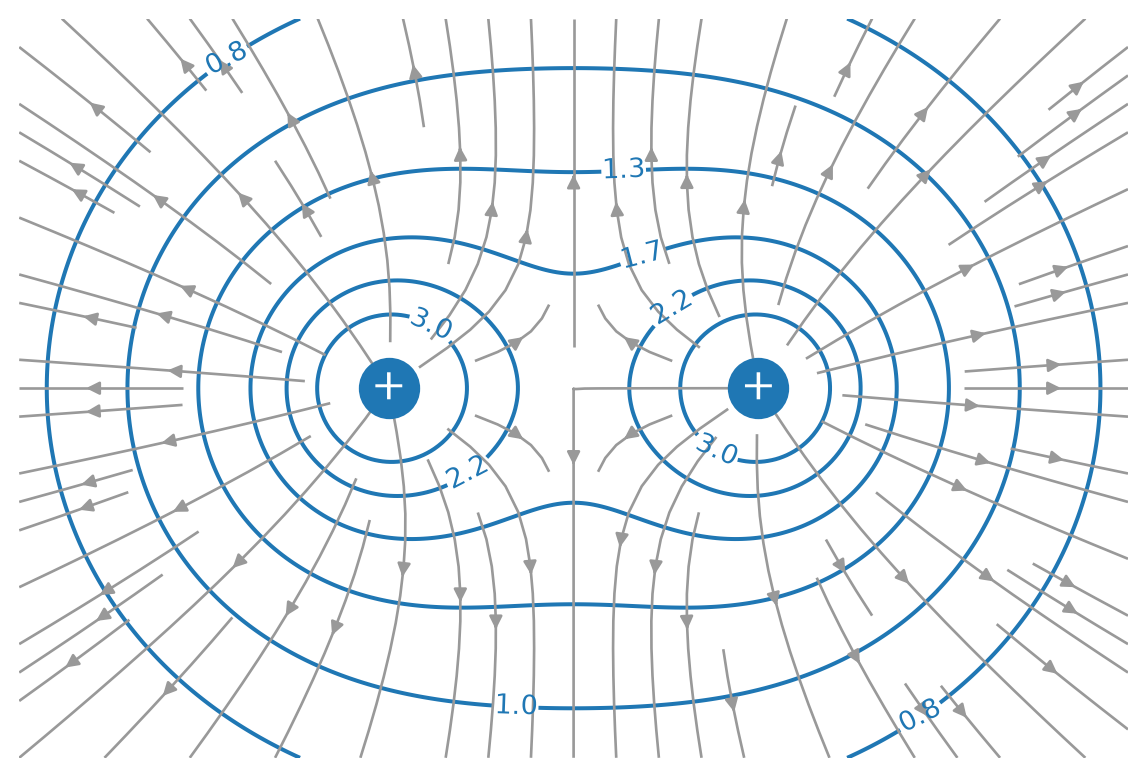

In [7]:
x, y = np.meshgrid(np.linspace(-3, 3, 300), np.linspace(-2, 2, 200))
charges = [(+1, -1.0), (+1, 1.0)]  # (z, x position)
phi = sum(z / np.hypot(x - x0, y) for z, x0 in charges)
Ex = sum(z * (x - x0) / np.hypot(x - x0, y) ** 3 for z, x0 in charges)
Ey = sum(z * y / np.hypot(x - x0, y) ** 3 for z, x0 in charges)

fig, ax = plt.subplots(figsize=(10, 5.0))
cs = ax.contour(
    x, y, phi, levels=[0.8, 1.0, 1.3, 1.7, 2.2, 3.0], colors="tab:blue", linewidths=1.5
)
ax.clabel(cs, fontsize=10)
ax.streamplot(x, y, Ex, Ey, color="0.6", density=0.9, linewidth=1)
for z, x0 in charges:
    ax.plot(x0, 0, "o", ms=22, color="tab:blue")
    ax.text(x0, 0, "+", ha="center", va="center", color="w", fontsize=16)
ax.set_aspect("equal")
ax.axis("off")
plt.show()

Blue: equipotentials, labelled with $\sum_i z_i/r_i$ (the potential in units of $k_BT/e$ when distances are measured in $\ell_B$). Grey: field lines. The field crosses equipotentials at right angles and points downhill in $\phi$.

## Dipole moment

For charges $q_i$ at positions $\mathbf r_i$:

$$\boldsymbol\mu = \sum_i q_i \mathbf r_i$$

- a vector; for a neutral set of charges it does not depend on the choice of origin
- two charges $\pm q$ a distance $d$ apart: $\mu = qd$, pointing from $-$ to $+$
- unit: the debye, $1\ \mathrm D = 3.336\times10^{-30}$ C·m, and $1\ e\cdot$Å $= 4.80$ D

Example: HCl has $\mu = 1.08$ D and bond length 1.27 Å, so the partial charges are

$$\delta = \frac{1.08}{4.80\times1.27}\,e \approx 0.18\,e$$

Water: $\mu = 1.85$ D. Dipoles are the topic of day 3.

## 8. The dielectric constant depends on temperature {.nostretch}

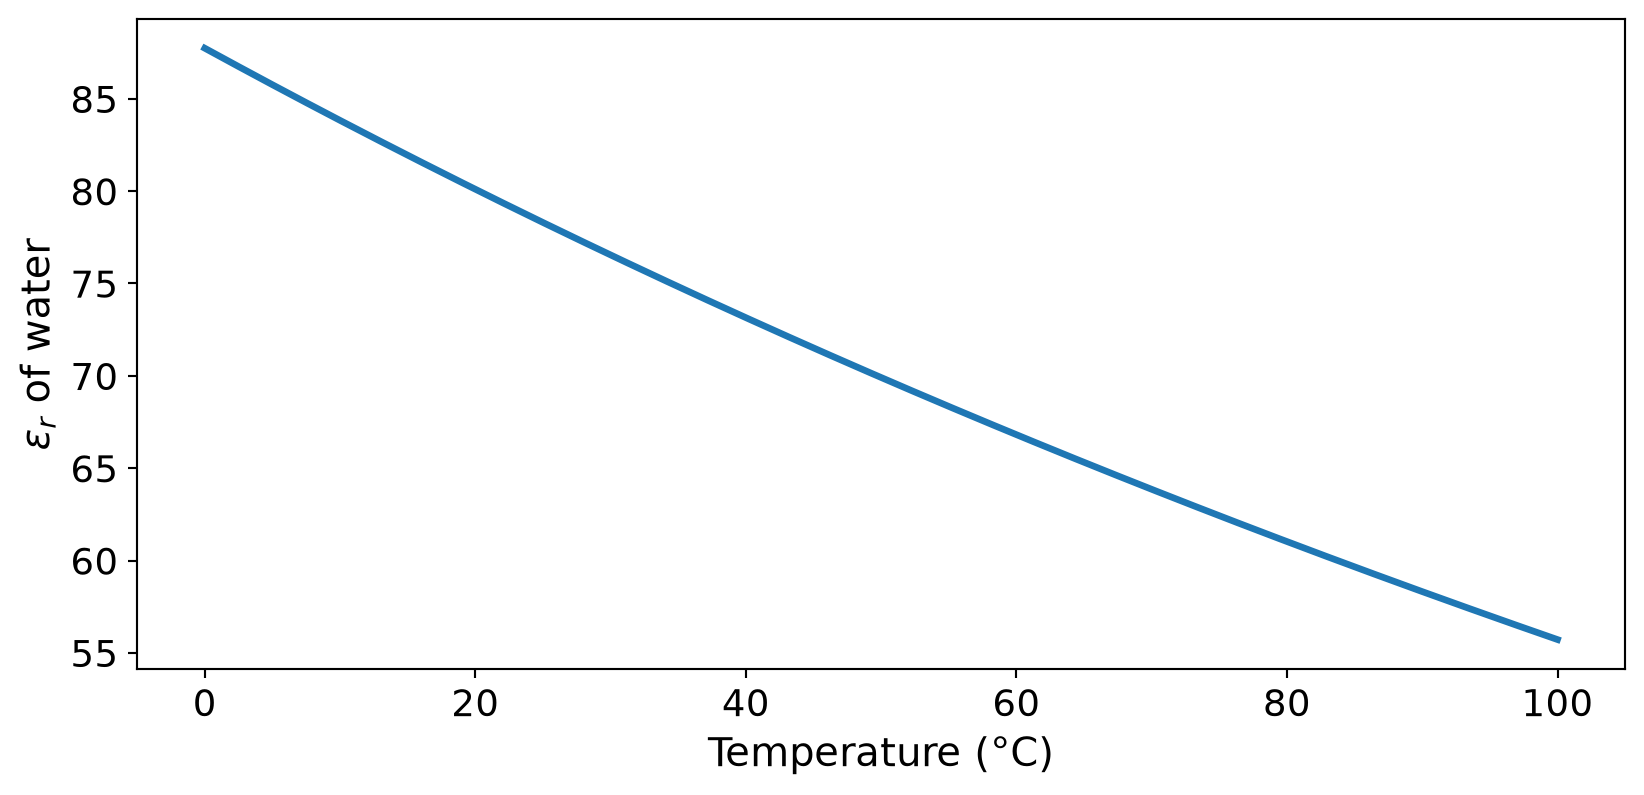

In [8]:
t = np.linspace(0, 100, 200)  # °C
# Malmberg & Maryott (1956) fit for water
eps = 87.740 - 0.40008 * t + 9.398e-4 * t**2 - 1.410e-6 * t**3

fig, ax = plt.subplots(figsize=(10, 4.4))
ax.plot(t, eps)
ax.set_xlabel("Temperature (°C)")
ax.set_ylabel(r"$\epsilon_r$ of water")
plt.show()

Thermal motion disturbs the alignment of water dipoles around charges, so screening weakens as $T$ rises (Dill Fig. 22.16). At 25 °C, $d\ln\epsilon_r/d\ln T \approx -1.36$.

## Coulomb's law in a medium is a free energy

Because $\epsilon_r$ depends on $T$, the work of bringing two charges together in a solvent,

$$A(r, T) = \frac{q_1 q_2}{4\pi\epsilon_0\epsilon_r(T)\,r},$$

is a **free energy**: it includes the rearrangement of the solvent. Thermodynamics then splits it:

$$S = -\frac{\partial A}{\partial T} = \frac{A}{\epsilon_r}\frac{d\epsilon_r}{dT}$$

$$U = A + TS = A\left(1 + \frac{d\ln\epsilon_r}{d\ln T}\right)$$

## Ion pairing in water is entropy driven

Water at 25 °C, $d\ln\epsilon_r/d\ln T \approx -1.36$:

$$TS \approx -1.36\,A, \qquad U \approx -0.36\,A$$

For oppositely charged ions moving closer, $A < 0$:

- the energy $U$ goes **up**
- the entropy term $TS$ is positive and larger
- the free energy decrease is entirely entropic

**Question:** What happens to the water molecules around the two ions when they come together? Why does that raise the entropy?

## Summary

- Coulomb's law $u = q_1q_2/4\pi\epsilon_0\epsilon_r r$: long-ranged and pairwise additive
- lattice energy: sum over all ions, Madelung constant $1.747$ for NaCl
- media screen charges; in water, ion pairs interact with only a few $k_BT$
- Bjerrum length: $u/k_BT = \ell_B z_1z_2/r$; 560 Å in vacuum, 7.1 Å in water
- energy and force, potential and field; superposition; dipole moment $\boldsymbol\mu = \sum_i q_i\mathbf r_i$
- $\epsilon_r(T)$ makes Coulomb's law in a medium a free energy; in water, ion pairing is entropy driven

**Now:** problems 1–5.
**Next time:** polar interactions: dipoles, polarization and dispersion.